# 01 · Preprocesamiento del dataset de especies animales

Este notebook convierte la tabla de animales en un **contexto formal** $(G, M, I)$: una tabla de objetos por atributos, con una marca donde el objeto tiene el atributo. Ese contexto es la entrada del resto del proyecto: los conceptos y el retículo (notebook 02) y las implicaciones y dependencias (notebook 03).

Pasos:

1. Cargar los datos.
2. Explorar las variables.
3. Revisar la calidad y la coherencia de los datos.
4. Decidir qué hacer con cada columna.
5. Discretizar las variables numéricas.
6. Aplicar el escalado conceptual para obtener el contexto formal.
7. Ver cómo cambia el tamaño del retículo con el número de intervalos.
8. Guardar los resultados.

- **Entrada:** `data/raw/animal_species_200_rows.csv`.
- **Salidas:** `data/processed/animales_discretizado.csv`, `data/processed/animales_contexto.csv` y `data/contexts/animales.cxt`.
- **Teoría:** sección 1 de [`docs/teoria/teoria.pdf`](../docs/teoria/teoria.pdf). Las referencias como «Proposición 1.12» o «§1.4» apuntan ahí.
- **Código:** [`scaler.md`](../docs/codigo/preprocessing/scaler.md), [`quantiles.md`](../docs/codigo/preprocessing/quantiles.md) y [`cuant_type.md`](../docs/codigo/preprocessing/cuant_type.md).

## 0. Configuración

In [2]:
import re
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd
from matplotlib.colors import ListedColormap

# Raíz del repositorio: la primera carpeta, de aquí hacia arriba, que tenga pyproject.toml.
RAIZ = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists()), None)
if RAIZ is None:
    raise FileNotFoundError("No se encontró pyproject.toml: abran Jupyter dentro de la carpeta del repositorio.")
if str(RAIZ / "src") not in sys.path:
    sys.path.insert(0, str(RAIZ / "src"))

from preprocessing.quantiles import methods          # reglas para k: sturges, freedman, scott
from preprocessing.cuant_type import cut_methods     # equal_width, equal_frequency, kmeans_1d
from preprocessing.scaler import discretize, scaling
from fca.context import FormalContext
from fca.lattice import concepts_cbo

DATOS_CRUDOS = RAIZ / "data" / "raw" / "animal_species_200_rows.csv"
CARPETA_PROCESADOS = RAIZ / "data" / "processed"
CARPETA_CONTEXTOS = RAIZ / "data" / "contexts"

pd.set_option("display.max_columns", 60)

# Estilo de las gráficas: marcas delgadas, ejes y rejilla discretos.
AZUL, NARANJA = "#2a78d6", "#eb6834"
TINTA, TINTA_SUAVE, GRIS = "#0b0b0b", "#52514e", "#898781"
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.edgecolor": "#c3c2b7",
    "axes.labelcolor": TINTA_SUAVE,
    "axes.titlesize": 11,
    "axes.titlecolor": TINTA,
    "axes.titlelocation": "left",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.axisbelow": True,
    "grid.color": "#e1e0d9",
    "grid.linewidth": 0.8,
    "xtick.color": "#c3c2b7",
    "ytick.color": "#c3c2b7",
    "xtick.labelcolor": TINTA_SUAVE,
    "ytick.labelcolor": TINTA_SUAVE,
    "legend.frameon": False,
})

Repositorio: PR-ABD


## 1. Carga de los datos

El archivo viene de Kaggle ([Animal Species Data](https://www.kaggle.com/datasets/kennyloic/animal-species-data)).

In [3]:
df = pd.read_csv(DATOS_CRUDOS)
print(f"{df.shape[0]} filas y {df.shape[1]} columnas")
df.head()

200 filas y 10 columnas


,Animal Type,Animal Name,Speed,Weight,Continent,Country,Lifespan,Migration,Reproduction,Threat Level
0,Insect,WalkingStick,8,349,Africa,Australia,93,No,Live,High
1,Bird,Hornbill,32,381,Africa,Brazil,2,Yes,Eggs,Medium
2,Bird,Hornbill,93,201,Europe,Germany,32,Yes,Live,High
3,Bird,Canary,85,21,Europe,Egypt,65,No,Eggs,Critical
4,Mammal,Lemur,40,80,Africa,Brazil,11,Yes,Live,Low


Para cada columna: su tipo, cuántos valores distintos tiene, cuántos faltan y algunos ejemplos.

In [4]:
estructura = pd.DataFrame({
    "tipo": df.dtypes.astype(str),
    "valores distintos": df.nunique(),
    "faltantes": df.isna().sum(),
    "ejemplos": [", ".join(map(str, df[col].unique()[:4])) for col in df.columns],
})
print("Filas repetidas:", df.duplicated().sum())
estructura

Filas repetidas: 0


,tipo,valores distintos,faltantes,ejemplos
Animal Type,object,5,0,"Insect, Bird, Mammal, Fish"
Animal Name,object,50,0,"WalkingStick, Hornbill, Canary, Lemur"
Speed,int64,94,0,"8, 32, 93, 85"
Weight,int64,156,0,"349, 381, 201, 21"
Continent,object,5,0,"Africa, Europe, America, Asia"
Country,object,10,0,"Australia, Brazil, Germany, Egypt"
Lifespan,int64,90,0,"93, 2, 32, 65"
Migration,object,2,0,"No, Yes"
Reproduction,object,2,0,"Live, Eggs"
Threat Level,object,4,0,"High, Medium, Critical, Low"


- `Speed`, `Weight` y `Lifespan` son numéricas: números enteros, con muchos valores distintos (entre 90 y 156). Habrá que discretizarlas (paso 5).
- Las otras siete columnas son texto (pandas las muestra como `object` o `str`, según la versión). `Migration` y `Reproduction` tienen dos valores, `Threat Level` tiene un orden natural y `Animal Name` tiene 50 valores.
- No faltan datos ni hay filas repetidas, así que no hay que imputar ni eliminar nada.

## 2. Exploración

### 2.1 Variables numéricas

In [5]:
NUMERICAS = ["Speed", "Weight", "Lifespan"]
df[NUMERICAS].describe().round(1)

,Speed,Weight,Lifespan
count,200.0,200.0,200.0
mean,62.1,236.3,52.9
std,33.3,139.6,29.8
min,1.0,1.0,2.0
25%,31.0,133.8,28.8
50%,64.0,218.5,50.5
75%,89.0,357.2,81.0
max,119.0,495.0,100.0


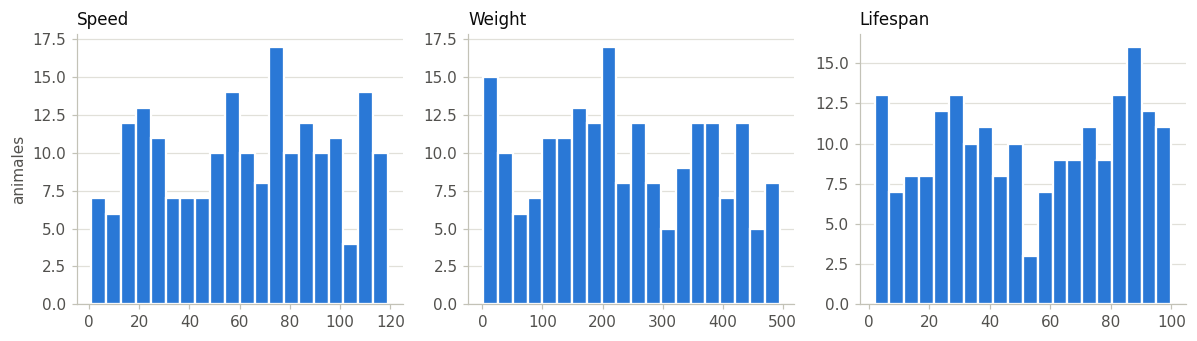

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(11, 3.2))
for ax, col in zip(axes, NUMERICAS):
    ax.hist(df[col], bins=20, color=AZUL, edgecolor="white", linewidth=1.5)
    ax.set_title(col)
    ax.grid(True, axis="y")
axes[0].set_ylabel("animales")
fig.tight_layout()
plt.show()

In [7]:
df[NUMERICAS].corr().round(2)

,Speed,Weight,Lifespan
Speed,1.00,0.04,0.02
Weight,0.04,1.00,0.00
Lifespan,0.02,0.00,1.00


Las tres variables cubren todo su rango de manera pareja, sin un pico claro ni valores atípicos: su distribución se parece a una uniforme. Además, las correlaciones son casi 0: conocer la velocidad de un animal no dice nada sobre su peso ni sobre su longevidad.

### 2.2 Variables categóricas

`Threat Level` se ordena de menor a mayor amenaza: Low < Medium < High < Critical. 

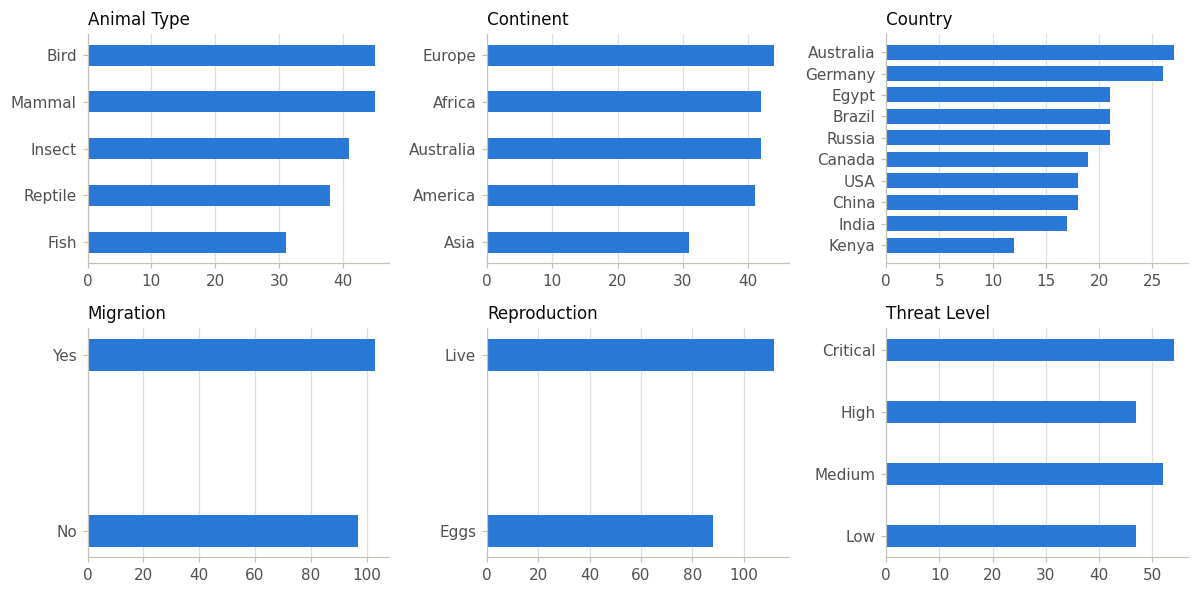

Animal Name: 50 nombres distintos; cada uno aparece entre 1 y 14 veces (Lemur es el más frecuente).


In [8]:
NIVELES_AMENAZA = ["Low", "Medium", "High", "Critical"]   # de menor a mayor amenaza
CATEGORICAS = ["Animal Type", "Continent", "Country", "Migration", "Reproduction", "Threat Level"]

fig, axes = plt.subplots(2, 3, figsize=(11, 5.5))
for ax, col in zip(axes.flat, CATEGORICAS):
    conteo = df[col].value_counts()
    conteo = conteo.reindex(NIVELES_AMENAZA) if col == "Threat Level" else conteo.sort_values()
    ax.barh(conteo.index, conteo.values, height=min(0.7, 0.09 * len(conteo)), color=AZUL)
    ax.set_title(col)
    ax.grid(True, axis="x")
fig.tight_layout()
plt.show()

nombres = df["Animal Name"].value_counts()
print(f"Animal Name: {len(nombres)} nombres distintos; cada uno aparece entre "
      f"{nombres.min()} y {nombres.max()} veces ({nombres.idxmax()} es el más frecuente).")

Los valores de cada variable están bastante balanceados: ninguno domina. `Animal Name` es casi un identificador, con 50 nombres para 200 filas.

## 3. Calidad y coherencia de los datos

No faltan datos, pero eso no garantiza que sean coherentes. Como FCA busca justamente relaciones entre atributos, conviene revisar si las columnas que deberían estar relacionadas lo están.

### 3.1 País y continente

Cada país debería aparecer en un solo continente.

In [9]:
pais_continente = pd.crosstab(df["Country"], df["Continent"])
pais_continente["continentes distintos"] = (pais_continente > 0).sum(axis=1)
pais_continente

Continent,Africa,America,Asia,Australia,Europe,continentes distintos
Country,,,,,,
Australia,8,7,3,4,5,5
Brazil,6,4,4,6,1,5
Canada,5,3,5,1,5,5
China,1,6,2,4,5,5
Egypt,5,2,3,4,7,5
Germany,3,7,2,6,8,5
India,4,5,2,3,3,5
Kenya,1,3,1,5,2,5
Russia,3,3,4,7,4,5


Los 10 países aparecen en los 5 continentes: hay registros de Brazil en Europe y de Kenya en Asia, por ejemplo. `Country` y `Continent` se contradicen, así que no tiene sentido usar las dos.

### 3.2 Tipo de animal y reproducción

Todas las aves ponen huevos (*Eggs*), y casi todos los mamíferos tienen crías vivas (*Live*): solo los monotremas, como el ornitorrinco, ponen huevos.

In [10]:
pd.crosstab(df["Animal Type"], df["Reproduction"])

Reproduction,Eggs,Live
Animal Type,,
Bird,23,22
Fish,10,21
Insect,13,28
Mammal,23,22
Reptile,19,19


En los datos, cerca de la mitad de las aves tiene crías vivas y cerca de la mitad de los mamíferos pone huevos: la reproducción no depende del tipo de animal.

### 3.3 Un mismo animal en varias filas

Cada nombre aparece en varias filas. Si las filas describieran especies, un mismo nombre tendría siempre los mismos valores. Para cada columna, la tabla da el mayor número de valores distintos que toma un mismo nombre:

In [11]:
display(df.groupby("Animal Name").nunique().max().to_frame("máximo de valores distintos por nombre"))
df[df["Animal Name"] == "Bison"]

,máximo de valores distintos por nombre
Animal Type,1
Speed,14
Weight,14
Continent,5
Country,7
Lifespan,12
Migration,2
Reproduction,2
Threat Level,4


,Animal Type,Animal Name,Speed,Weight,Continent,Country,Lifespan,Migration,Reproduction,Threat Level
15,Mammal,Bison,14,197,America,China,39,Yes,Live,Critical
64,Mammal,Bison,51,280,Africa,Egypt,89,Yes,Eggs,Low
101,Mammal,Bison,117,485,America,Brazil,50,Yes,Eggs,Low
122,Mammal,Bison,15,144,America,Russia,93,Yes,Live,Medium
168,Mammal,Bison,86,190,Asia,Brazil,26,Yes,Live,Critical
169,Mammal,Bison,15,162,Europe,Canada,28,Yes,Live,Low


Solo `Animal Type` vale 1: un Bison siempre es Mammal. Todo lo demás cambia de una fila a otra. Los seis Bison, por ejemplo, tienen velocidades entre 14 y 117, y dos de ellos ponen huevos.

En términos de bases de datos, se cumple la dependencia funcional `Animal Name → Animal Type`, y `Animal Name` no determina ninguna otra columna. 

### Conclusión de la revisión

Todo indica que los datos se generaron al azar: salvo el tipo de cada animal, los valores no dependen del animal ni están relacionados entre sí. Eso no impide usar el dataset, pero cambia lo que se puede concluir con él:

- **Sirve para lo que se planeó:** depurar y validar los algoritmos, y medir tamaños y tiempos en un caso de tamaño realista.
- **No sirve para sacar conclusiones sobre los animales.** Los conceptos e implicaciones que aparezcan describen estas 200 filas, no a las especies reales. Por ejemplo, «todo mamífero tiene crías vivas» no se va a cumplir.
- **Es un buen punto de comparación.** En un dataset con estructura real, como Breast Cancer Wisconsin, se espera encontrar implicaciones con más soporte que aquí.

## 4. Decisiones para cada columna

| Columna | Qué es | Tratamiento |
|---|---|---|
| `Animal Type` | nominal, 5 valores | escala nominal |
| `Animal Name` | casi un identificador, 50 valores | fuera del contexto |
| `Speed`, `Weight`, `Lifespan` | numéricas, entre 90 y 156 valores distintos | discretización y escala ordinal |
| `Continent` | nominal, 5 valores | escala nominal |
| `Country` | nominal, 10 valores, contradice a `Continent` | fuera del contexto |
| `Migration`, `Reproduction` | binarias | escala nominal |
| `Threat Level` | ordinal, 4 valores | escala ordinal |

- **`Animal Name` queda fuera** porque agregaría 50 atributos de unos 4 objetos cada uno, que llenarían el retículo de conceptos pequeños. Se conserva en la tabla discretizada (paso 8) para estudiar dependencias funcionales.
- **`Country` queda fuera** porque contradice a `Continent` (paso 3.1), y se prefiere `Continent` por tener menos valores. También se conserva en la tabla discretizada.
- **Las binarias usan escala nominal**, con dos atributos: `Migration=Yes` y `Migration=No`. En FCA la ausencia de un atributo no es un atributo, así que con solo `Migration=Yes` el grupo de los que no migran no podría aparecer en ninguna intensión.
- **`Threat Level` usa escala ordinal** porque sus valores tienen orden: `Threat Level<=Medium` reúne a los animales con amenaza Low o Medium.

Las decisiones quedan en la celda siguiente. 

In [12]:
EXCLUIDAS = ["Animal Name", "Country"]                       # no entran al contexto
NOMINALES = ["Animal Type", "Continent", "Migration", "Reproduction"]
ORDINALES = NUMERICAS + ["Threat Level"]                     # las numéricas, ya discretizadas

METODO = "equal_frequency"   # "equal_width", "equal_frequency" o "kmeans_1d"
K = 4                        # intervalos por variable, o una regla: "sturges", "freedman", "scott"
INTERORDINAL = False         # False: atributos «<=»; True: «<=» y «>=» (escala interordinal)

asignadas = EXCLUIDAS + NOMINALES + ORDINALES
assert sorted(asignadas) == sorted(df.columns), "Cada columna debe estar en exactamente una lista."

# Los objetos G son las 200 filas. Se nombran con el animal y el número de fila
# (por ejemplo, Bison_15) para reconocerlos en las tablas y los diagramas.
df.index = [f"{nombre}_{fila}" for fila, nombre in enumerate(df["Animal Name"])]
df.index.name = "objeto"
df.head(3)

,Animal Type,Animal Name,Speed,Weight,Continent,Country,Lifespan,Migration,Reproduction,Threat Level
objeto,,,,,,,,,,
WalkingStick_0,Insect,WalkingStick,8,349,Africa,Australia,93,No,Live,High
Hornbill_1,Bird,Hornbill,32,381,Africa,Brazil,2,Yes,Eggs,Medium
Hornbill_2,Bird,Hornbill,93,201,Europe,Germany,32,Yes,Live,High


## 5. Discretización de las variables numéricas

Una escala necesita pocos valores, y estas variables tienen entre 90 y 156. La discretización (§1.4) parte el rango de cada variable en k intervalos ordenados y cambia cada valor por el número de su intervalo: 0, 1, …, k − 1. Es el único paso que pierde información: dos animales con valores distintos que caen en el mismo intervalo quedan iguales.

### 5.1 ¿Cuántos intervalos?

El proyecto tiene tres reglas para elegir k (§1.5): Sturges, Freedman–Diaconis y Scott.

In [13]:
pd.DataFrame({regla: {col: elegir_k(df[col]) for col in NUMERICAS}
              for regla, elegir_k in methods.items()})

,sturges,freedman,scott
Speed,9,6,6
Weight,9,7,6
Lifespan,9,6,6


Las reglas sugieren entre 6 y 9 intervalos. Pero están pensadas para que un histograma estime bien una densidad (Observación 1.34), no para FCA, donde cada intervalo se vuelve un atributo y el número de conceptos crece rápido con k (se mide en el paso 7). Por eso se usa k = 4, como propone el plan del proyecto: con igual frecuencia, los cortes son los cuartiles q1, q2 y q3.

### 5.2 ¿Qué método?

Cuántos animales quedan en cada intervalo con cada método, usando el `K` del paso 4:

In [14]:
tamanos = {}
for metodo in cut_methods:
    codigos, _ = discretize(df[NUMERICAS], metodo, K)
    tamanos[metodo] = {col: np.bincount(codigos[col]).tolist() for col in NUMERICAS}
pd.DataFrame(tamanos)

,equal_width,equal_frequency,kmeans_1d
Speed,"[49, 48, 54, 49]","[51, 50, 50, 49]","[55, 44, 53, 48]"
Weight,"[49, 62, 45, 44]","[50, 50, 50, 50]","[42, 60, 42, 56]"
Lifespan,"[48, 53, 38, 61]","[50, 50, 52, 48]","[48, 53, 41, 58]"


Como los datos son casi uniformes, los tres métodos dan intervalos parecidos. Se usa **igual frecuencia** porque garantiza intervalos balanceados (Proposición 1.22): unos 50 animales en cada uno, así que ningún atributo queda con muy pocos objetos. Con valores atípicos la diferencia sería mayor: el método de igual ancho puede dejar intervalos casi vacíos (§1.4).

### 5.3 Discretizar

`discretize` aplica el método a todas las columnas numéricas que recibe. Devuelve la tabla con los códigos y el número de intervalos de cada columna:

In [15]:
disc, ks = discretize(df[NUMERICAS], METODO, K)
print("Intervalos por variable:", ks)
disc.head()

Intervalos por variable: {'Speed': 4, 'Weight': 4, 'Lifespan': 4}


,Speed,Weight,Lifespan
objeto,,,
WalkingStick_0,0,2,3
Hornbill_1,1,3,0
Hornbill_2,3,1,1
Canary_3,2,0,2
Lemur_4,1,0,0


Qué valores quedaron en cada intervalo:

In [16]:
intervalos = pd.concat(
    {col: df[col].groupby(disc[col]).agg(["min", "max", "count"]) for col in NUMERICAS},
    names=["variable", "código"],
).rename(columns={"min": "mínimo", "max": "máximo", "count": "animales"})
intervalos

mínimo  máximo  animales
variable código                          
Speed    0            1      31        51
         1           32      64        50
         2           65      89        50
         3           90     119        49
Weight   0            1     130        50
         1          135     216        50
         2          221     357        50
         3          358     495        50
Lifespan 0            2      28        50
         1           29      50        50
         2           51      81        52
         3           82     100        48

Con los valores por defecto, el código 0 de `Speed` reúne a los animales con velocidad entre 1 y 31, el código 1 a los que tienen entre 32 y 64, y así sucesivamente. Los códigos conservan el orden de los valores (Proposición 1.19): si un animal es más rápido que otro, su código es mayor o igual. Por eso se les puede aplicar una escala ordinal.

En la gráfica, cada línea es un corte entre dos intervalos, y su etiqueta es el atributo que va a generar en el paso 6.

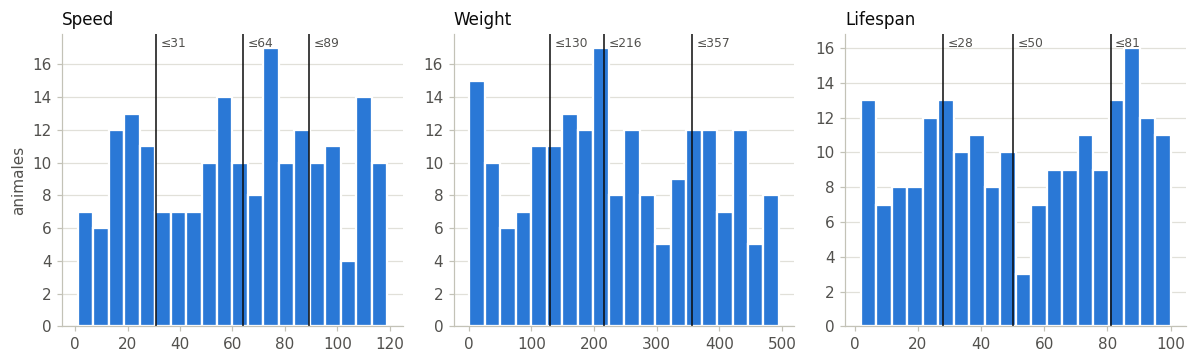

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(11, 3.4))
for ax, col in zip(axes, NUMERICAS):
    ax.hist(df[col], bins=20, color=AZUL, edgecolor="white", linewidth=1.5)
    for maximo in intervalos.loc[col, "máximo"].iloc[:-1]:   # el último intervalo no tiene corte
        ax.axvline(maximo, color=TINTA, linewidth=1)
        ax.annotate(f"≤{maximo}", (maximo, 1), xycoords=("data", "axes fraction"),
                    xytext=(3, -2), textcoords="offset points", va="top", fontsize=8, color=TINTA_SUAVE)
    ax.set_title(col)
    ax.grid(True, axis="y")
axes[0].set_ylabel("animales")
fig.tight_layout()
plt.show()

## 6. Escalado conceptual: el contexto formal

El escalado (§1.2 y §1.3) convierte cada variable en atributos binarios:

- **Escala nominal**, `scaling(datos, "nominal")`: un atributo `variable=valor` por cada valor. Cada objeto tiene exactamente uno por variable (Proposición 1.12).
- **Escala ordinal creciente**, `scaling(datos, "ordinal", "le")`: un atributo `variable<=v` por cada valor v. Un objeto con valor 1 tiene `<=1`, `<=2`, …: los atributos de una variable forman una cadena (Proposición 1.13).

### 6.1 Variables ordinales

`scaling` ordena los valores con `np.unique`. Con texto, el orden sería alfabético (Critical < High < Low < Medium), así que primero `Threat Level` se pasa a números en el orden correcto. Las numéricas ya son códigos de 0 a k − 1.

In [18]:
codigo_amenaza = {nivel: i for i, nivel in enumerate(NIVELES_AMENAZA)}   # Low -> 0, ..., Critical -> 3
ordinales = disc.assign(**{"Threat Level": df["Threat Level"].map(codigo_amenaza)})

I_ordinal = scaling(ordinales, "ordinal", "le")
if INTERORDINAL:   # escala interordinal: se agregan los atributos «>=» (Observación 1.11)
    I_ordinal = pd.concat([I_ordinal, scaling(ordinales, "ordinal", "ge")], axis=1)
list(I_ordinal.columns)

['Speed<=0',
 'Speed<=1',
 'Speed<=2',
 'Speed<=3',
 'Weight<=0',
 'Weight<=1',
 'Weight<=2',
 'Weight<=3',
 'Lifespan<=0',
 'Lifespan<=1',
 'Lifespan<=2',
 'Lifespan<=3',
 'Threat Level<=0',
 'Threat Level<=1',
 'Threat Level<=2',
 'Threat Level<=3']

Los nombres usan los códigos: `Speed<=1` significa «el código de Speed es como mucho 1». Por la Proposición 1.19, eso equivale a «Speed es como mucho el máximo del intervalo 1», así que el atributo se renombra `Speed<=64`, que se entiende sin consultar la tabla de intervalos. Lo mismo para `>=`, con el mínimo del intervalo, y para los niveles de amenaza. Solo cambian los nombres: la matriz es la misma.

In [19]:
legibles = {}
for col in NUMERICAS:
    tabla = intervalos.loc[col]
    for codigo, minimo, maximo in zip(tabla.index, tabla["mínimo"], tabla["máximo"]):
        legibles[f"{col}<={codigo}"] = f"{col}<={maximo}"   # código <= j  <=>  valor <= máximo del intervalo j
        legibles[f"{col}>={codigo}"] = f"{col}>={minimo}"   # código >= j  <=>  valor >= mínimo del intervalo j
for nivel, i in codigo_amenaza.items():
    legibles[f"Threat Level<={i}"] = f"Threat Level<={nivel}"
    legibles[f"Threat Level>={i}"] = f"Threat Level>={nivel}"

I_ordinal = I_ordinal.rename(columns=legibles)
list(I_ordinal.columns)

['Speed<=31',
 'Speed<=64',
 'Speed<=89',
 'Speed<=119',
 'Weight<=130',
 'Weight<=216',
 'Weight<=357',
 'Weight<=495',
 'Lifespan<=28',
 'Lifespan<=50',
 'Lifespan<=81',
 'Lifespan<=100',
 'Threat Level<=Low',
 'Threat Level<=Medium',
 'Threat Level<=High',
 'Threat Level<=Critical']

### 6.2 Variables nominales

In [20]:
I_nominal = scaling(df[NOMINALES], "nominal")
list(I_nominal.columns)

['Animal Type=Bird',
 'Animal Type=Fish',
 'Animal Type=Insect',
 'Animal Type=Mammal',
 'Animal Type=Reptile',
 'Continent=Africa',
 'Continent=America',
 'Continent=Asia',
 'Continent=Australia',
 'Continent=Europe',
 'Migration=No',
 'Migration=Yes',
 'Reproduction=Eggs',
 'Reproduction=Live']

### 6.3 Unir los bloques y quitar los atributos universales

Al unir los dos bloques se obtiene la matriz de incidencia. El último atributo de cada escala ordinal (`Speed<=119`, …) lo tienen todos los objetos: es un atributo universal (Corolario 1.14). Como aparece en todas las intensiones y no cambia la estructura del retículo, se quita.

In [21]:
I_completo = pd.concat([I_ordinal, I_nominal], axis=1)
universales = I_completo.columns[I_completo.all()]
I = I_completo.drop(columns=universales)

print("Atributos universales quitados:", list(universales))
print(f"Contexto formal: |G| = {I.shape[0]} objetos y |M| = {I.shape[1]} atributos")
I.head().astype(int)

Atributos universales quitados: ['Speed<=119', 'Weight<=495', 'Lifespan<=100', 'Threat Level<=Critical']
Contexto formal: |G| = 200 objetos y |M| = 26 atributos


,Speed<=31,Speed<=64,Speed<=89,Weight<=130,Weight<=216,Weight<=357,Lifespan<=28,Lifespan<=50,Lifespan<=81,Threat Level<=Low,Threat Level<=Medium,Threat Level<=High,Animal Type=Bird,Animal Type=Fish,Animal Type=Insect,Animal Type=Mammal,Animal Type=Reptile,Continent=Africa,Continent=America,Continent=Asia,Continent=Australia,Continent=Europe,Migration=No,Migration=Yes,Reproduction=Eggs,Reproduction=Live
objeto,,,,,,,,,,,,,,,,,,,,,,,,,,
WalkingStick_0,1,1,1,0,0,1,0,0,0,0,0,1,0,0,1,0,0,1,0,0,0,0,1,0,0,1
Hornbill_1,0,1,1,0,0,0,1,1,1,0,1,1,1,0,0,0,0,1,0,0,0,0,0,1,1,0
Hornbill_2,0,0,0,0,1,1,0,1,1,0,0,1,1,0,0,0,0,0,0,0,0,1,0,1,0,1
Canary_3,0,0,1,1,1,1,0,0,1,0,0,0,1,0,0,0,0,0,0,0,0,1,1,0,1,0
Lemur_4,0,1,1,1,1,1,1,1,1,1,1,1,0,0,0,1,0,1,0,0,0,0,0,1,0,1


### 6.4 Comprobaciones

Tres propiedades que el contexto tiene que cumplir. 

In [22]:
# Proposición 1.12: cada objeto tiene exactamente un atributo de cada variable nominal.
for col in NOMINALES:
    bloque = I.loc[:, I.columns.str.startswith(f"{col}=")]
    assert (bloque.sum(axis=1) == 1).all(), col

# Proposición 1.13: los atributos «<=» de cada variable forman una cadena:
# quien tiene uno, tiene también todos los que están a su derecha.
for col in ORDINALES:
    bloque = I.loc[:, I.columns.str.startswith(f"{col}<=")].to_numpy()
    assert (bloque[:, :-1] <= bloque[:, 1:]).all(), col

# Proposición 1.19: los nombres nuevos dicen la verdad. Por ejemplo, el atributo
# «Speed<=31» lo tienen exactamente los animales con Speed <= 31.
for col in NUMERICAS:
    for nombre in I.columns[I.columns.str.startswith(col)]:
        valor = float(nombre[len(col) + 2:])
        esperado = df[col] <= valor if "<=" in nombre else df[col] >= valor
        assert I[nombre].equals(esperado), nombre

print("Las tres comprobaciones pasaron.")

Las tres comprobaciones pasaron.


### 6.5 Así se ve el contexto

Cada fila de la imagen es un atributo y cada columna un objeto; el azul indica que el objeto tiene el atributo. Los objetos se ordenaron para que los parecidos queden juntos.

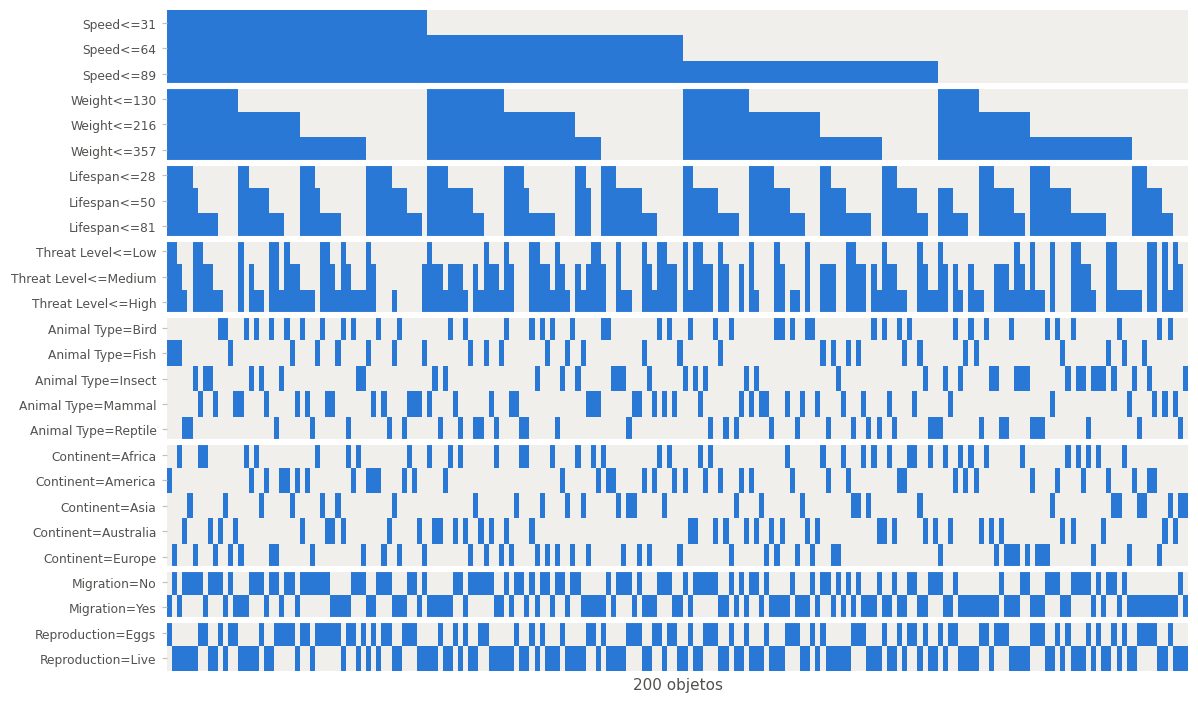

In [23]:
orden = I.sort_values(list(I.columns), ascending=False).index     # agrupa objetos parecidos
fig, ax = plt.subplots(figsize=(11, 6.5))
ax.imshow(I.loc[orden].T.to_numpy(), aspect="auto", interpolation="nearest",
          cmap=ListedColormap(["#f0efec", AZUL]))
ax.set_yticks(range(I.shape[1]), I.columns, fontsize=8)
ax.set_xticks([])
ax.set_xlabel(f"{I.shape[0]} objetos")
ax.spines[:].set_visible(False)

# Una franja blanca separa los atributos de cada variable.
variable = [re.split("<=|>=|=", atributo)[0] for atributo in I.columns]
for j in range(1, len(variable)):
    if variable[j] != variable[j - 1]:
        ax.axhline(j - 0.5, color="white", linewidth=4)
fig.tight_layout()
plt.show()

Se ven las propiedades comprobadas arriba. En cada bloque nominal (`Animal Type`, `Continent`, …) cada columna tiene exactamente una marca. En cada bloque ordinal, las marcas de una columna empiezan en algún atributo y siguen hasta el último del bloque, porque forman una cadena; o no hay ninguna, si el valor está en el intervalo más alto.

La discretización puede dejar a dos objetos con la misma fila aunque sus valores originales sean distintos (Corolario 1.17). Esos objetos ya no se pueden separar: aparecen juntos en todos los conceptos del retículo.

In [24]:
repetidos = I[I.duplicated(keep=False)]
print(f"{I.drop_duplicates().shape[0]} filas distintas entre {I.shape[0]} objetos; "
      f"{len(repetidos)} objetos comparten su fila con otro.")
repetidos.astype(int)

199 filas distintas entre 200 objetos; 2 objetos comparten su fila con otro.


,Speed<=31,Speed<=64,Speed<=89,Weight<=130,Weight<=216,Weight<=357,Lifespan<=28,Lifespan<=50,Lifespan<=81,Threat Level<=Low,Threat Level<=Medium,Threat Level<=High,Animal Type=Bird,Animal Type=Fish,Animal Type=Insect,Animal Type=Mammal,Animal Type=Reptile,Continent=Africa,Continent=America,Continent=Asia,Continent=Australia,Continent=Europe,Migration=No,Migration=Yes,Reproduction=Eggs,Reproduction=Live
objeto,,,,,,,,,,,,,,,,,,,,,,,,,,
SpeckledRacer_56,0,0,0,0,0,1,1,1,1,0,0,1,0,0,0,0,1,0,0,0,0,1,0,1,1,0
MudTurtle_117,0,0,0,0,0,1,1,1,1,0,0,1,0,0,0,0,1,0,0,0,0,1,0,1,1,0


## 7. Tamaño del retículo según k

El número de conceptos depende mucho de k y de la escala. Para medirlo, la función siguiente repite los pasos 5 y 6 con otros parámetros (sin los nombres legibles, que no cambian la matriz). Luego se cuentan los conceptos con el algoritmo Close-by-One del proyecto (`fca/lattice.py`, que se estudia en el notebook 02).

In [25]:
amenaza = df["Threat Level"].map(codigo_amenaza)

def contexto_animales(k, interordinal=False, metodo=METODO):
    """Repite los pasos 5 y 6 con otros parámetros y devuelve la matriz de incidencia."""
    codigos, _ = discretize(df[NUMERICAS], metodo, k)
    ordinales = codigos.assign(**{"Threat Level": amenaza})
    bloques = [scaling(ordinales, "ordinal", "le")]
    if interordinal:
        bloques.append(scaling(ordinales, "ordinal", "ge"))
    bloques.append(scaling(df[NOMINALES], "nominal"))
    J = pd.concat(bloques, axis=1)
    return J.loc[:, ~J.all()]            # sin atributos universales

# Con los parámetros del paso 4 se obtiene la misma matriz que en el paso 6.
assert np.array_equal(contexto_animales(K, INTERORDINAL).to_numpy(), I.to_numpy())

In [26]:
filas = []
for k in range(2, 7):
    fila = {"k": k}
    for escala in ("ordinal", "interordinal"):
        J = contexto_animales(k, interordinal=(escala == "interordinal"))
        fila[f"atributos {escala}"] = J.shape[1]
        inicio = time.perf_counter()
        fila[f"conceptos {escala}"] = len(concepts_cbo(FormalContext(J)))
        fila[f"segundos {escala}"] = round(time.perf_counter() - inicio, 2)
    filas.append(fila)

tamano = pd.DataFrame(filas).set_index("k")
tamano

,atributos ordinal,conceptos ordinal,segundos ordinal,atributos interordinal,conceptos interordinal,segundos interordinal
k,,,,,,
2,20,2431,0.01,26,9936,0.05
3,23,4636,0.02,32,30923,0.19
4,26,7387,0.03,38,75152,0.58
5,29,10339,0.06,44,142333,1.40
6,32,13699,0.08,50,258223,2.75


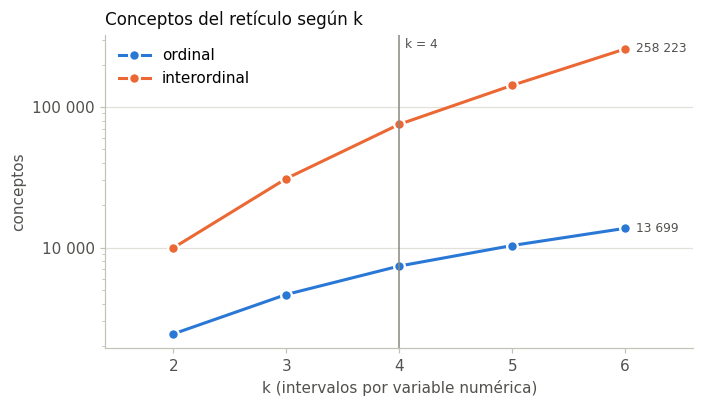

In [27]:
fig, ax = plt.subplots(figsize=(6.5, 3.8))
for escala, color in (("ordinal", AZUL), ("interordinal", NARANJA)):
    serie = tamano[f"conceptos {escala}"]
    ax.plot(serie.index, serie, color=color, linewidth=2, marker="o", markersize=7,
            markeredgecolor="white", markeredgewidth=1.5, label=escala)
    ax.annotate(f"{serie.iloc[-1]:,}".replace(",", " "), (serie.index[-1], serie.iloc[-1]),
                xytext=(7, 0), textcoords="offset points", va="center", fontsize=8, color=TINTA_SUAVE)
if isinstance(K, int):
    ax.axvline(K, color=GRIS, linewidth=1)
    ax.annotate(f"k = {K}", (K, 1), xycoords=("data", "axes fraction"), xytext=(4, -2),
                textcoords="offset points", va="top", fontsize=8, color=TINTA_SUAVE)
ax.set_yscale("log")
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v:,.0f}".replace(",", " ")))
ax.set_xticks(tamano.index)
ax.margins(x=0.15)
ax.set_xlabel("k (intervalos por variable numérica)")
ax.set_ylabel("conceptos")
ax.set_title("Conceptos del retículo según k")
ax.grid(True, axis="y")
ax.legend(loc="upper left")
fig.tight_layout()
plt.show()

- Con escala ordinal, el número de conceptos crece de forma aproximadamente lineal con k; con la interordinal crece mucho más rápido: con k = 4 ya son unas diez veces más.
- Contarlos tarda a lo sumo unos segundos, pero ningún retículo de estos tamaños se puede dibujar: `plot_lattice` avisa por encima de 150 conceptos.
- **Elección: k = 4 con escala ordinal.** La escala interordinal permite atributos como «rápido» (`Speed>=90`) e intervalos («Speed entre 32 y 64»), que con solo `<=` no existen, porque la ausencia de un atributo no es un atributo. Si el grupo los necesita, basta con poner `INTERORDINAL = True` en el paso 4, a cambio de un retículo unas diez veces más grande.

## 8. Guardar los resultados

| Archivo | Contenido | Para qué |
|---|---|---|
| `data/processed/animales_discretizado.csv` | La tabla original con los códigos de intervalo en las columnas numéricas, incluidas `Animal Name` y `Country` | Dependencias funcionales y claves (notebook 03) |
| `data/processed/animales_contexto.csv` | El contexto formal: 1 si el objeto tiene el atributo y 0 si no | Conceptos, retículo e implicaciones (notebooks 02 y 03) |
| `data/contexts/animales.cxt` | El mismo contexto en formato Burmeister, el estándar de los programas de FCA | Abrirlo en un programa como ConExp para comparar resultados |

In [28]:
CARPETA_PROCESADOS.mkdir(parents=True, exist_ok=True)
CARPETA_CONTEXTOS.mkdir(parents=True, exist_ok=True)

discretizado = df.assign(**{col: disc[col] for col in NUMERICAS})
discretizado.to_csv(CARPETA_PROCESADOS / "animales_discretizado.csv")
I.astype(int).to_csv(CARPETA_PROCESADOS / "animales_contexto.csv")

def guardar_cxt(I, ruta):
    """Formato Burmeister: 'B', los tamaños, los nombres y una fila de X y . por objeto."""
    lineas = ["B", "", str(I.shape[0]), str(I.shape[1]), ""]
    lineas += [str(g) for g in I.index] + [str(m) for m in I.columns]
    lineas += ["".join("X" if v else "." for v in fila) for fila in I.to_numpy()]
    ruta.write_text("\n".join(lineas) + "\n", encoding="utf-8", newline="\n")

guardar_cxt(I, CARPETA_CONTEXTOS / "animales.cxt")

# Comprobación: al volver a leer el CSV se obtiene exactamente el mismo contexto.
leido = pd.read_csv(CARPETA_PROCESADOS / "animales_contexto.csv", index_col=0).astype(bool)
assert leido.equals(I)

for ruta in (CARPETA_PROCESADOS / "animales_discretizado.csv",
             CARPETA_PROCESADOS / "animales_contexto.csv",
             CARPETA_CONTEXTOS / "animales.cxt"):
    print(f"{ruta.relative_to(RAIZ).as_posix():44s} {ruta.stat().st_size / 1024:5.1f} KB")

data/processed/animales_discretizado.csv      12.5 KB
data/processed/animales_contexto.csv          13.1 KB
data/contexts/animales.cxt                     8.1 KB


## 9. Resumen

In [29]:
print(f"Método: {METODO} · intervalos: {ks} · escala: {'interordinal' if INTERORDINAL else 'ordinal'}")
print(f"Contexto: {I.shape[0]} objetos × {I.shape[1]} atributos · proporción de marcas: {I.to_numpy().mean():.2f}")
print(f"Conceptos: {len(concepts_cbo(FormalContext(I))):,}".replace(",", " "))

Método: equal_frequency · intervalos: {'Speed': 4, 'Weight': 4, 'Lifespan': 4} · escala: ordinal
Contexto: 200 objetos × 26 atributos · proporción de marcas: 0.38
Conceptos: 7 387


- El dataset tiene 200 filas y 10 columnas, sin faltantes ni filas repetidas, pero parece generado al azar: la única relación real es `Animal Name → Animal Type`. Sirve para validar los algoritmos, no para sacar conclusiones sobre los animales.
- Con las decisiones por defecto (igual frecuencia, k = 4, escala ordinal, sin `Animal Name` ni `Country`), el contexto tiene 200 objetos, 26 atributos y 7 387 conceptos.
- En el notebook 03 aparecerán implicaciones que vienen de la escala y no de los datos, como `Speed<=31 → Speed<=64` (Observación 1.15). Habrá que separarlas de las que sí dicen algo sobre los datos.

En los notebooks siguientes, el contexto se carga con:

```python
I = pd.read_csv(RAIZ / "data" / "processed" / "animales_contexto.csv", index_col=0).astype(bool)
```